Síntesis de Gini vs. Entropía sobre la Misma Variable

En este notebook se aborda el **Paso 4** de la práctica 4:
Elegir una misma variable categórica y calcular sobre ella tanto la **Entropía de Shannon** (heterogeneidad/diversidad) como el **Coeficiente de Gini** aplicado a las frecuencias de sus categorías (concentración/desigualdad), contrastando ambos resultados.

In [1]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import sys

sys.path.append("..")
from src.cleaning.limpiado import limpiar_datos
from src.models.heterogeneidad import entropia
from src.models.concentracion import gini_array
from config.rutas import RUTA_DATOS_CRUDOS

df_limpio = limpiar_datos(RUTA_DATOS_CRUDOS)
print("Datos cargados correctamente. Total de filas:", df_limpio.shape[0])

Datos cargados correctamente. Total de filas: 24560


Seleccionamos la variable categórica `estrato_socioeconomico` (y `nivel_escolaridad`), calculamos sus frecuencias absolutas y relativas $p_i$.

In [2]:
variable_seleccionada = "estrato_socioeconomico"

tabla_frec = (
    df_limpio[variable_seleccionada]
    .value_counts()
    .with_columns([
        (pl.col("count") / pl.col("count").sum()).alias("prop")
    ])
    .sort("prop", descending=True)
)

tabla_frec

estrato_socioeconomico,count,prop
i64,u32,f64
2,13020,0.53013
3,5450,0.221906
1,4154,0.169137
4,1936,0.078827


## Cálculo de la Entropía de Shannon y Coeficiente de Gini

In [3]:
k = tabla_frec.shape[0]  # Número de categorías
p = tabla_frec["prop"].to_numpy()

H = entropia(variable_seleccionada, base=2)
H_max = np.log2(k)
H_normalizada = H / H_max if H_max > 0 else 0

G = gini_array(p)

print(f"Variable analizada: {variable_seleccionada}")
print(f"Número de categorías (k): {k}")
print(f"Entropía de Shannon (H): {H:.4f} bits (Máxima posible: {H_max:.4f})")
print(f"Entropía relativa/normalizada (H / H_max): {H_normalizada:.4f}")
print(f"Coeficiente de Gini de frecuencias (G): {G:.4f}")

Variable analizada: estrato_socioeconomico
Número de categorías (k): 4
Entropía de Shannon (H): 1.6899 bits (Máxima posible: 2.0000)
Entropía relativa/normalizada (H / H_max): 0.8449
Coeficiente de Gini de frecuencias (G): 0.3517


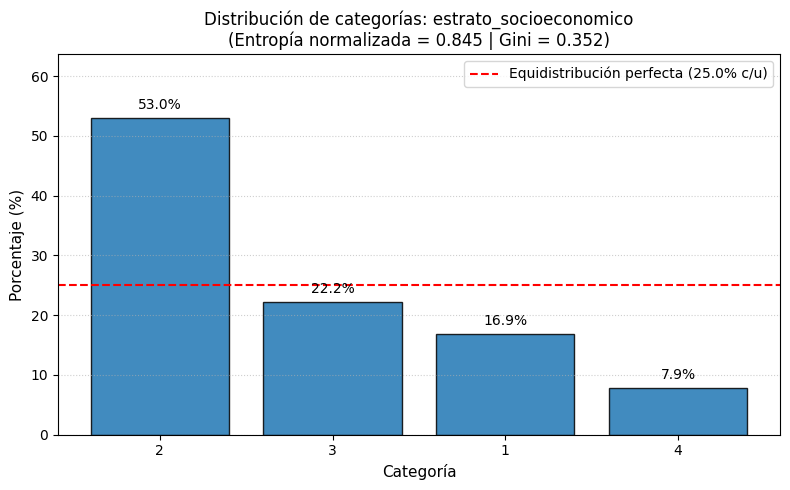

In [ ]:
categorias = [str(c) for c in tabla_frec[variable_seleccionada].to_list()]
porcentajes = (tabla_frec["prop"] * 100).to_list()

plt.figure(figsize=(8, 5))
barras = plt.bar(categorias, porcentajes, color="#1f77b4", edgecolor="black", alpha=0.85)

# Línea de equidistribución ideal (100% / k) en este caso es el 25% porque k=4
plt.axhline(100 / k, color="red", linestyle="--", label=f"Equidistribución perfecta ({100/k:.1f}% c/u)")

plt.title(f"Distribución de categorías: {variable_seleccionada}\n(Entropía normalizada = {H_normalizada:.3f} | Gini = {G:.3f})", fontsize=12)
plt.xlabel("Categoría", fontsize=11)
plt.ylabel("Porcentaje (%)", fontsize=11)
plt.ylim(0, max(porcentajes) * 1.2)
plt.legend()
plt.grid(axis="y", linestyle=":", alpha=0.6)

for bar in barras:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 1,
             f"{height:.1f}%", ha="center", va="bottom", fontsize=10)

plt.tight_layout()
plt.show()

## Comparación Conceptual e Interpretación de Resultados: Entropía vs. Gini

### 1. Diferencia Conceptual entre Ambos Índices
> La **Entropía de Shannon** describe la *diversidad, dispersión e incertidumbre* presente en la distribución categórica: alcanza su valor máximo cuando las observaciones se reparten de manera perfectamente uniforme entre todas las clases ( = 1/k$), señalando una heterogeneidad total y máxima imprevisibilidad. En contraste, el **Coeficiente de Gini** aplicado sobre las frecuencias de dichas categorías mide la *desigualdad o concentración relativa*: cuantifica qué tan alejada está la distribución real de una igualdad de tamaños, aproximándose a 1 si una sola categoría acapara casi la totalidad de las observaciones (monopolio categórico) y a 0 cuando todas tienen la misma participación. En resumen, mientras la entropía evalúa qué tan balanceadas y diversas están las alternativas, el Gini mide el grado de concentración o asimetría con que las categorías dominantes absorben la muestra.

### 2. Interpretación Concreta de los Resultados ()
* **Entropía Normalizada ( / H_{max} = 0.845$):** Indica una **alta diversidad (84.5% de la entropía máxima)**. Esto confirma que los casos reportados están repartidos a lo largo de todos los estratos socioeconómicos y no están colapsados en un solo nivel.
* **Coeficiente de Gini ( = 0.352$):** Muestra una **desigualdad/concentración moderada**. En la gráfica se observa claramente que el **Estrato 2 (Medio Bajo) concentra más de la mitad del total de casos (53.0%)**, sobrepasando holgadamente la línea de equidistribución del 25%, mientras que el **Estrato 4 (Alto) apenas representa el 7.9%**. Esta asimetría en las barras es la que eleva el coeficiente de Gini.
